In [ ]:

%load_ext autoreload
%autoreload 2
import time
import sys
import numpy as np
import Components as comp
import socket
import random
import Measurement_functions as mf
if socket.gethostname() == "ph-photonbec5":
    sys.path.append("D:/Control/PythonPackages/")
    sys.path.append("D:/Control/PiezoController/")






In [ ]:
laser = comp.Toptica_Laser()
plot_flag_g2 = True
binning= 7 # This determines the timing resolution, i.e. -> b : bin, r : resolution (ps) -> r = 2^b ps
offset = 0
tacq = 20000 # Measurement time in millisec, you can change this
number_of_measurements = 1
position = 0
power_list = np.arange(18.5,21,0.5)/1000
# resolution_list = [2,3,4,5,6,7,8,9,10,11,12,13,14,15,16]
resolution_list = [6,7,8]
position_list = np.arange(0,650,50)

with comp.Translation_Stage() as stage:
    for position in position_list:
        stage.set(position)
        print('Position is : ', position)
        for power in power_list:
            print('Power = ', power*1000, 'mW')
            laser.set(power)
            time.sleep(0.1)
            random.shuffle(resolution_list)
            for n in resolution_list:
                scan = mf.get_hh_data(n, offset, tacq,plot_flag_g2)
                data = scan[0]
                resolution = scan[1]
                mf.save_hh_data(data, resolution, tacq,power*1000,position)

laser.set(0)


In [ ]:
#laser = comp.Toptica_Laser()
#components = dict()
#components.update({"powermeter": comp.Thor_PowerMeter(power_meter_usb_name='USB0::0x1313::0x8078::P0034379::INSTR', num_power_readings=10, bs_factor=1, wavelength=950)})
# filter_wheel = comp.FilterWheel(allowed_filter_positions=[0, 1, 2, 3, 4, 5])
#__________________________________________________________________G2 PARAMETERS____________________________________________________________________________________________
plot_flag_g2 = True
binning= 10 # This determines the timing resolution, i.e. : b : bin, r : resolution (ps) -> r = 2^b ps
offset = 0
tacq = 20000 # Measurement time in millisec, you can change this
number_of_measurements = 1
#__________________________________________________________MEASUREMENT PARAMETERS____________________________________________________________________________________________
#power_list = np.append(np.append(np.arange(17.75,18.350,0.1)/1000,np.arange(18.350,20.250,0.1)/1000),np.arange(20.250,22.250,0.25)/1000) #CHANGE HERE
position_list = np.array([0])
power_list = np.arange(17.34,18.5,0.02)/1000
filter_list = [0,1]
position = 20
for power in power_list:
    print('Power = ', power*1000, 'mW')
    laser.set2(power)
    time.sleep(1)

    for n in range(number_of_measurements):
        scan = mf.get_hh_data(binning, offset, tacq,plot_flag_g2)
        data = scan[0]
        resolution = scan[1]
        mf.save_hh_data(data, resolution, tacq,power*1000,position,10**6*components['powermeter'].take_power_reading())

laser.set(0)

In [ ]:
plot_flag_g2 = True
binning= 4
# You can change this sets the resolution as well
offset = 0
tacq = 30000 # Measurement time in millisec, you can change this
power = 25/1000
position_list = np.arange(0,650,50)
resolution_list = [5,6,7,8,9]
n_meas = 1

with comp.Translation_Stage() as stage:

    for position in position_list:
        stage.set(position)
        print('Position is : ', position)
        time.sleep(0.2)
        for k in range(n_meas):
            scan = mf.get_hh_data(binning, offset, tacq,plot_flag_g2)
            data = scan[0]
            resolution = scan[1]
            mf.save_hh_data(data, resolution, tacq,power*1000,position)



In [ ]:

%load_ext autoreload
%autoreload 2
import time
import sys
import numpy as np
import Components as comp
import socket
import random
import Measurement_functions as mf
import matplotlib.pyplot as plt
if socket.gethostname() == "ph-photonbec5":
    sys.path.append("D:/Control/PythonPackages/")
    sys.path.append("D:/Control/PiezoController/")
plot_flag_g2 = False
binning= 7
# You can change this sets the resolution as well
offset = 0
tacq = 10000 # Measurement time in millisec, you can change this
power = 17.36/1000
position = 20



scan = mf.get_hh_data(binning, offset, tacq,plot_flag_g2)
data = scan[0]
resolution = scan[1]
mf.save_hh_data(data, resolution, tacq,power*1000,position)
counts = data/np.mean(data[350:500])
x = np.arange(0,len(counts),1)*0.128
plt.figure(figsize=(10, 6))
plt.plot(x,counts, label='Counts (Channel 0)')
plt.title('Counts vs. Time Bin (Channel 0)')
plt.xlabel('Time Bin')
plt.ylabel('Counts')
plt.xlim(0,80)
plt.ylim(np.min(counts[0:350]-0.025),np.max(counts)+0.025)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
plt.plot(data/np.max(data))
plt.xlim(0,800)
plt.ylim(0.97,1)

In [ ]:
laser = comp.Toptica_Laser()
# filter_wheel = comp.FilterWheel(allowed_filter_positions=[0, 1, 2, 3, 4, 5])
#__________________________________________________________________G2 PARAMETERS____________________________________________________________________________________________
plot_flag_g2 = True
binning= 10 # This determines the timing resolution, i.e. : b : bin, r : resolution (ps) -> r = 2^b ps
offset = 0
tacq = 20000 # Measurement time in millisec, you can change this
number_of_measurements = 1
#__________________________________________________________MEASUREMENT PARAMETERS____________________________________________________________________________________________
#power_list = np.append(np.append(np.arange(17.75,18.350,0.1)/1000,np.arange(18.350,20.250,0.1)/1000),np.arange(20.250,22.250,0.25)/1000) #CHANGE HERE
position_list = np.array([0])
power_list = np.arange(14,14.8,0.025)/1000
filter_list = [0,1]
position = 0
for power in power_list:
    print('Power = ', power*1000, 'mW')
    laser.set2(power)
    time.sleep(1)

    for n in range(number_of_measurements):
        scan = mf.get_hh_data(binning, offset, tacq,plot_flag_g2)
        data = scan[0]
        resolution = scan[1]
        mf.save_hh_data(data, resolution, tacq,power*1000,position)
laser.set(0)

Power =  8.6 mW
Resolution is 128.0ps


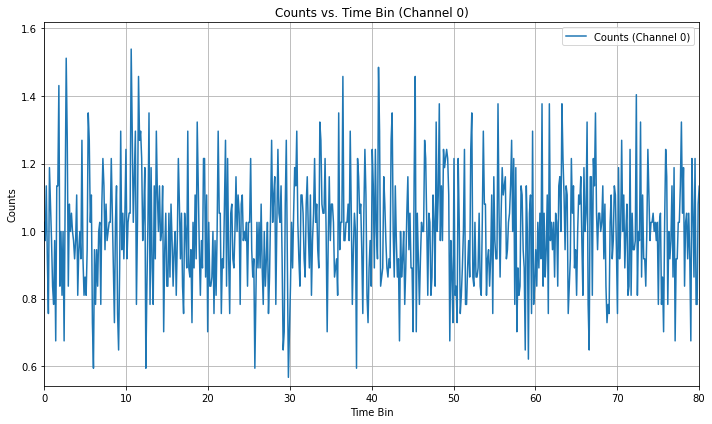

Power =  8.62 mW
Resolution is 128.0ps


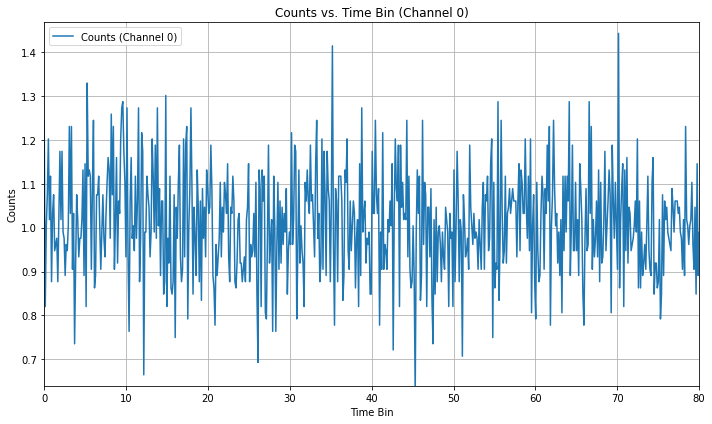

Power =  8.639999999999999 mW
Resolution is 128.0ps


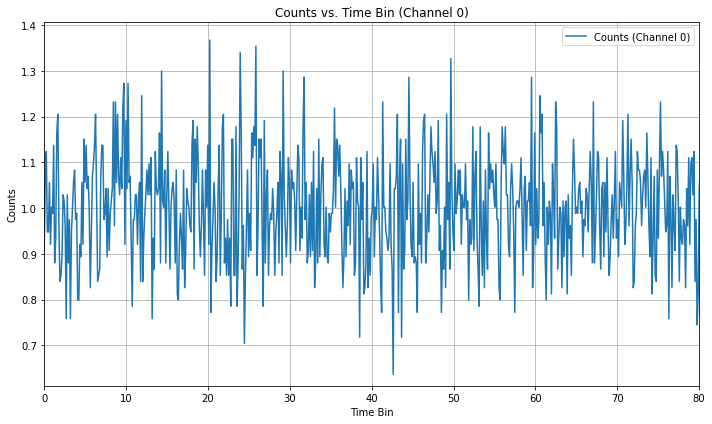

Power =  8.659999999999998 mW
Resolution is 128.0ps


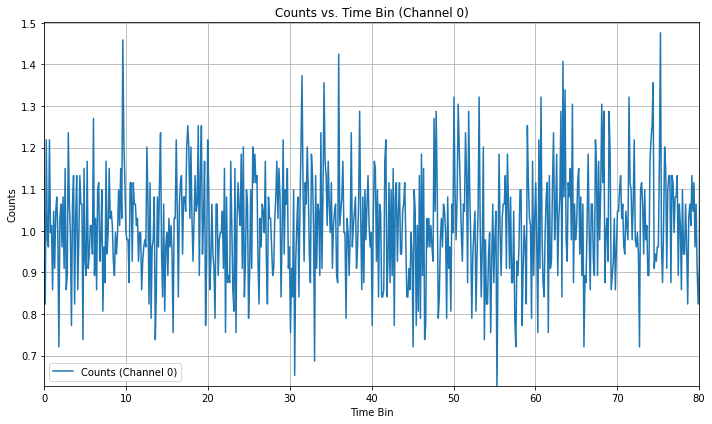

Power =  8.679999999999998 mW
Resolution is 128.0ps


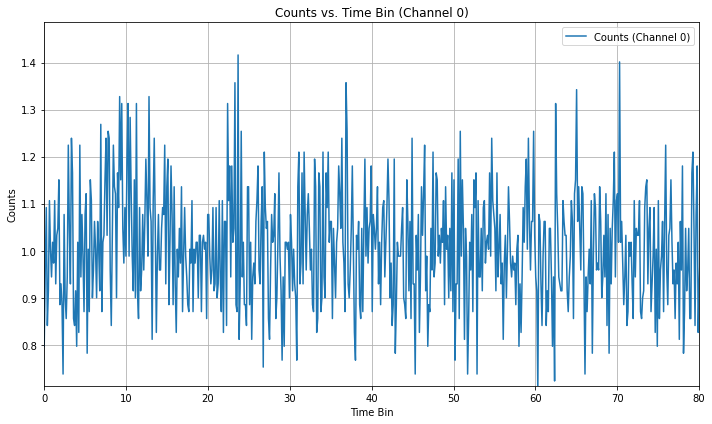

Power =  8.699999999999998 mW
Resolution is 128.0ps


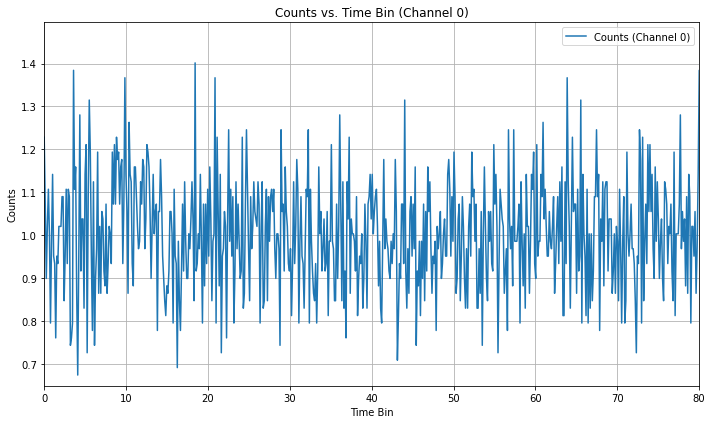

Power =  8.719999999999997 mW
Resolution is 128.0ps


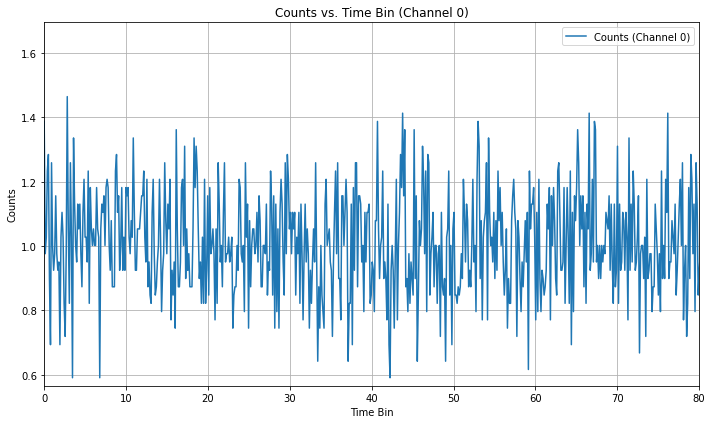

Power =  8.739999999999997 mW
Resolution is 128.0ps


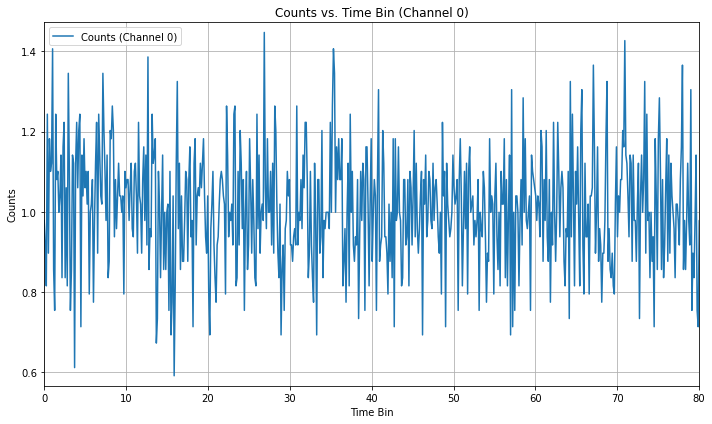

Power =  8.759999999999996 mW
Resolution is 128.0ps


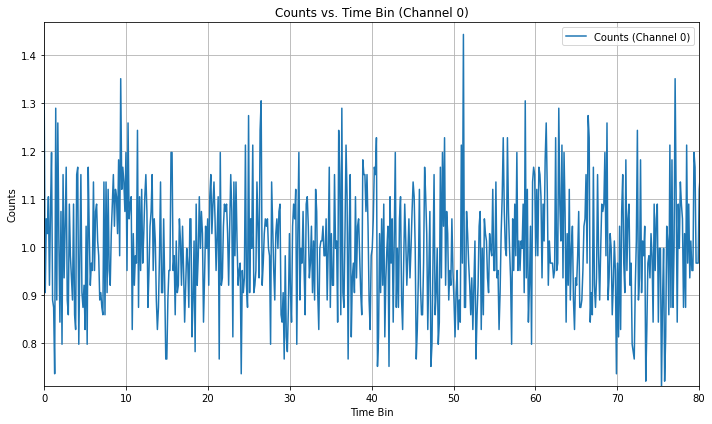

Power =  8.779999999999996 mW
Resolution is 128.0ps


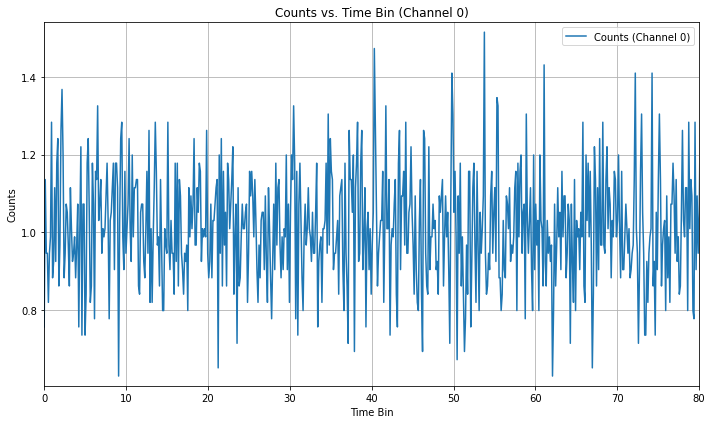

Power =  8.799999999999995 mW
Resolution is 128.0ps


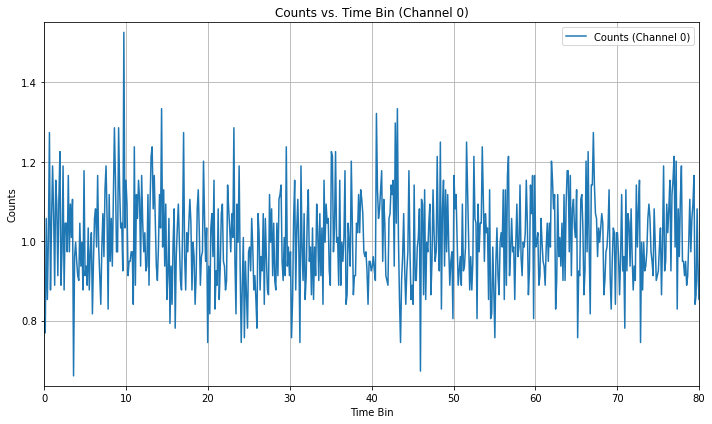

Power =  8.819999999999995 mW
Resolution is 128.0ps


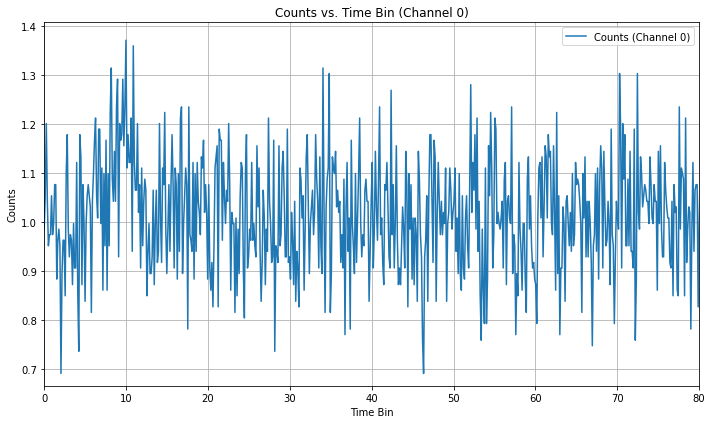

Power =  8.839999999999995 mW
Resolution is 128.0ps


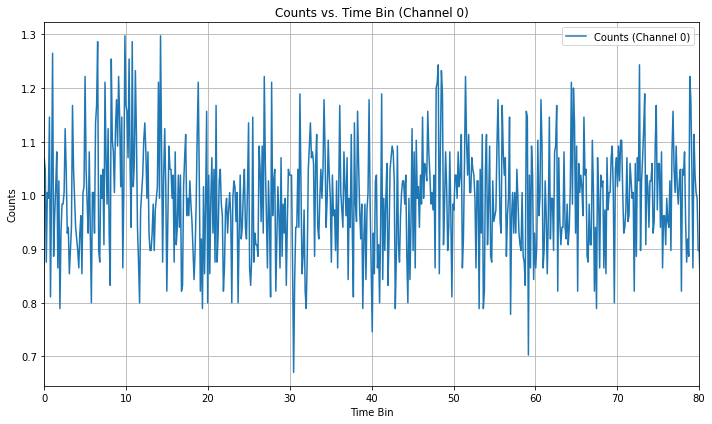

Power =  8.859999999999994 mW
Resolution is 128.0ps


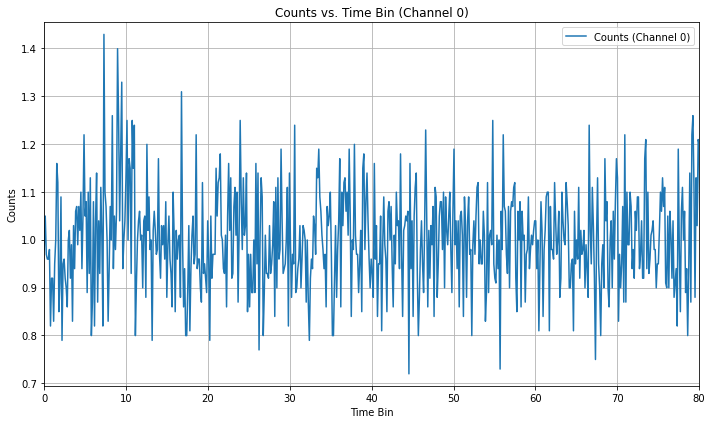

Power =  8.879999999999994 mW
Resolution is 128.0ps


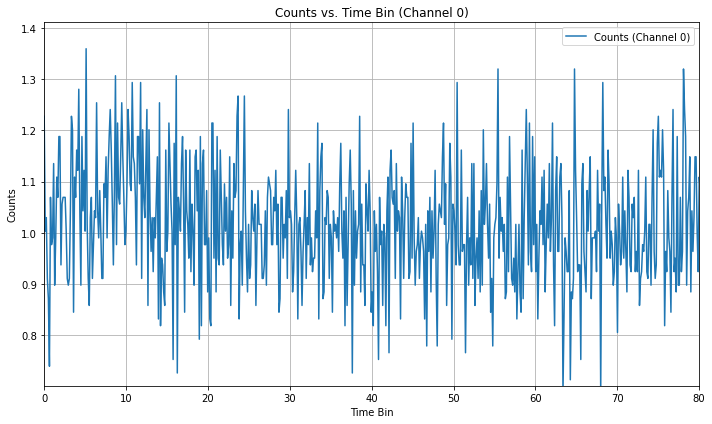

Power =  8.899999999999993 mW
Resolution is 128.0ps


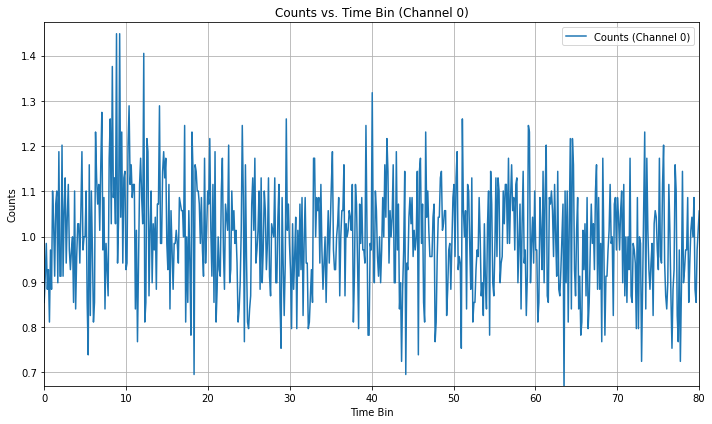

Power =  8.919999999999993 mW
Resolution is 128.0ps


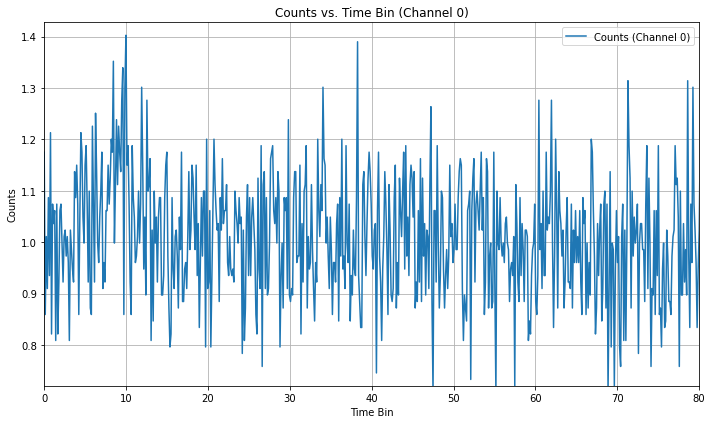

Power =  8.939999999999992 mW
Resolution is 128.0ps


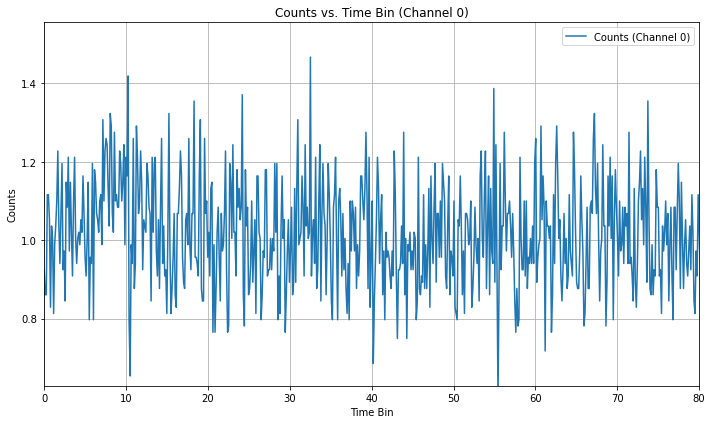

Power =  8.959999999999992 mW
Resolution is 128.0ps


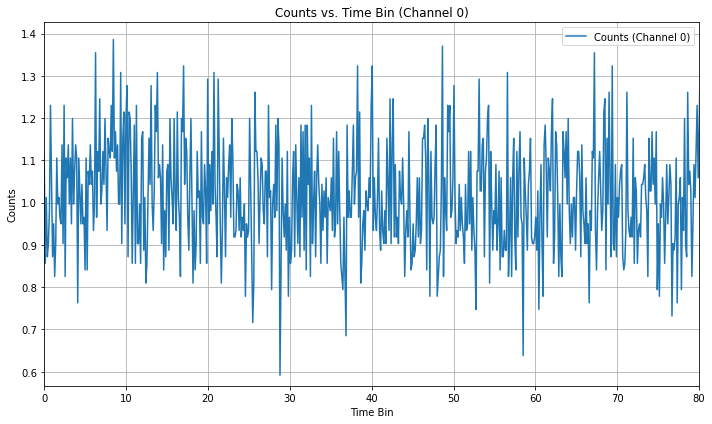

Power =  8.979999999999992 mW
Resolution is 128.0ps


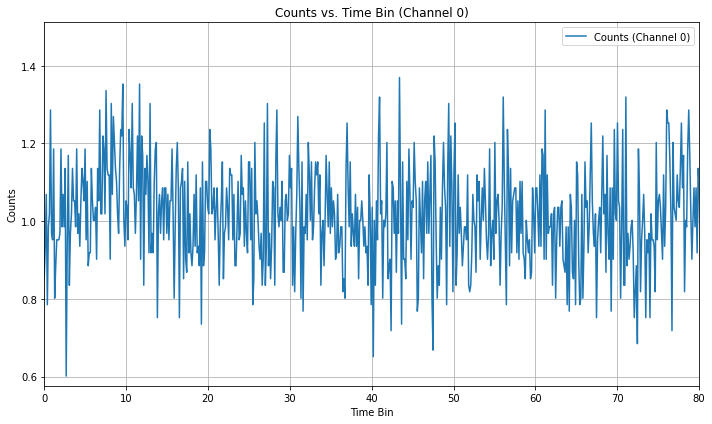

Power =  8.999999999999991 mW
Resolution is 128.0ps


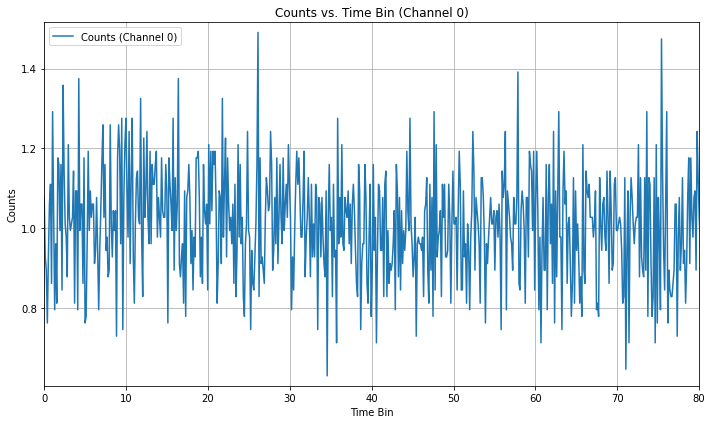

Power =  9.01999999999999 mW
Resolution is 128.0ps


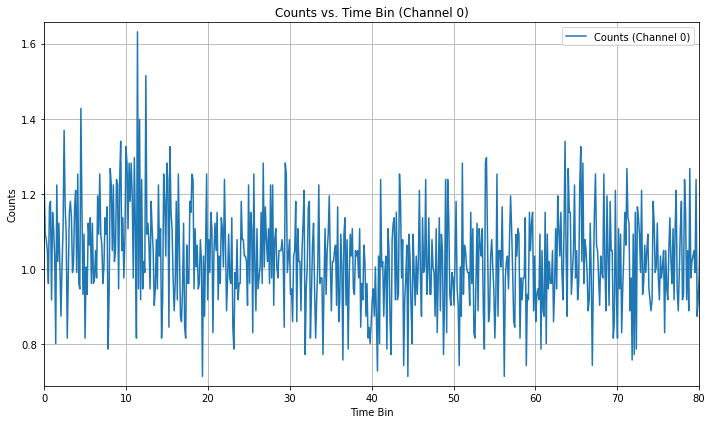

Power =  9.03999999999999 mW
Resolution is 128.0ps


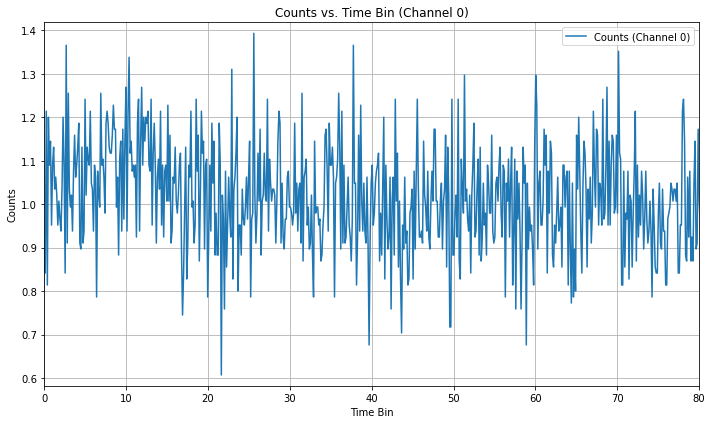

Power =  9.05999999999999 mW
Resolution is 128.0ps


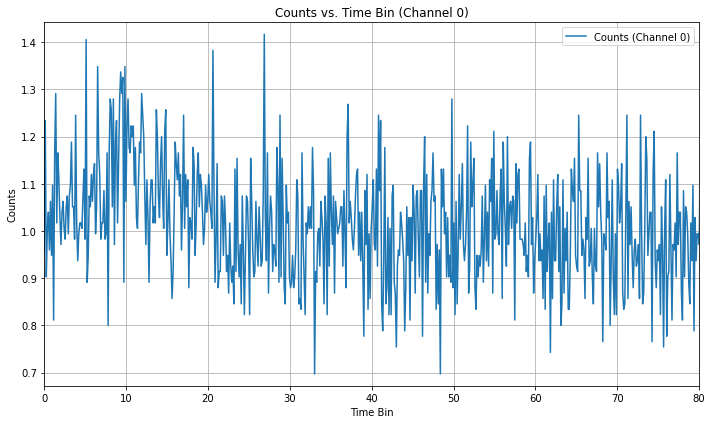

Power =  9.07999999999999 mW
Resolution is 128.0ps


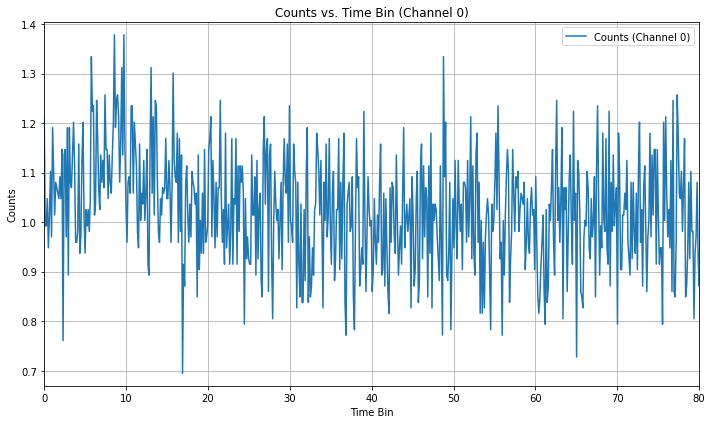

Power =  9.099999999999989 mW
Resolution is 128.0ps


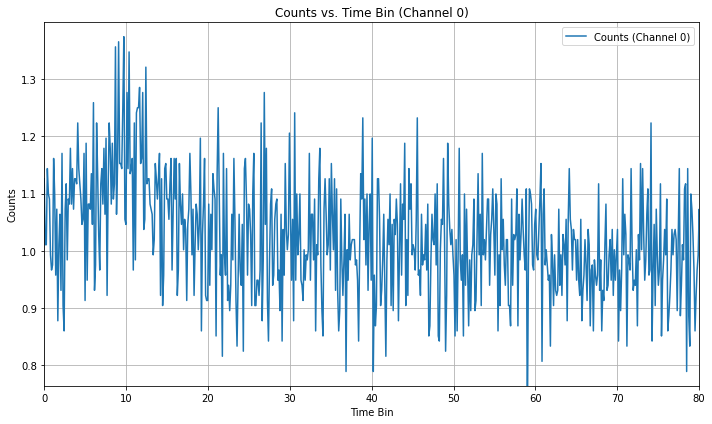

Power =  9.119999999999989 mW
Resolution is 128.0ps


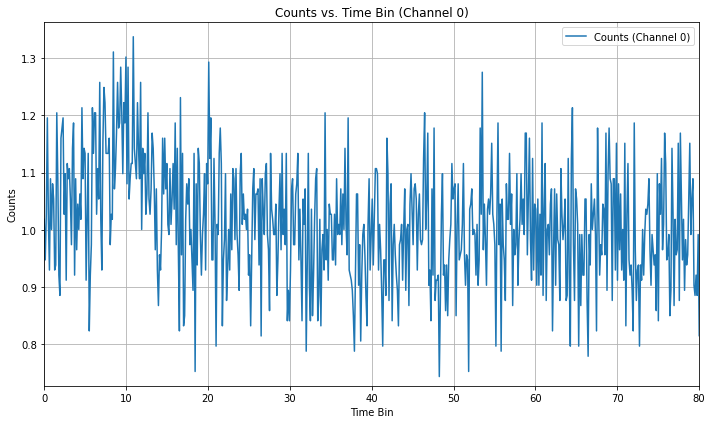

Power =  9.139999999999988 mW
Resolution is 128.0ps


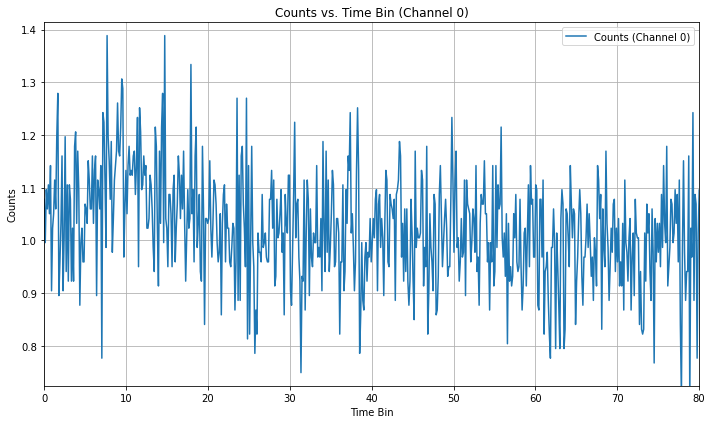

Power =  9.159999999999988 mW
Resolution is 128.0ps


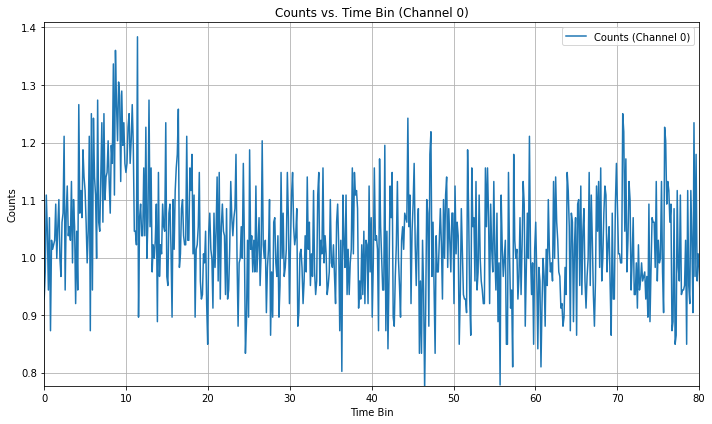

Power =  9.179999999999987 mW
Resolution is 128.0ps


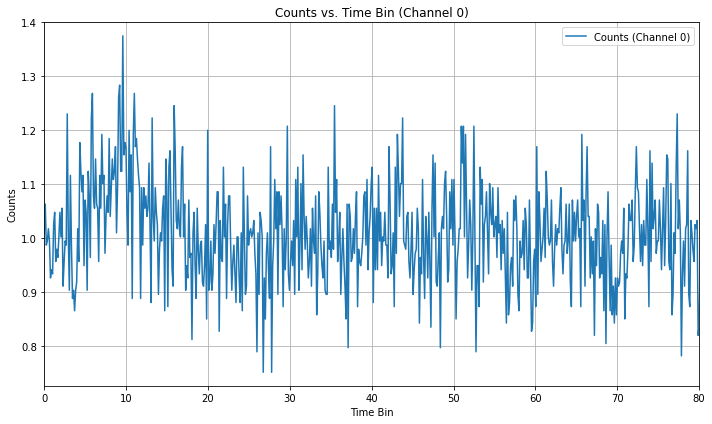

Power =  9.199999999999987 mW
Resolution is 128.0ps


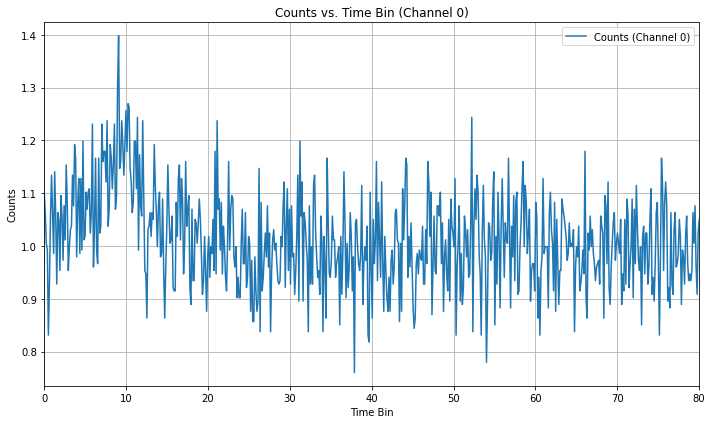

Power =  9.219999999999986 mW
Resolution is 128.0ps


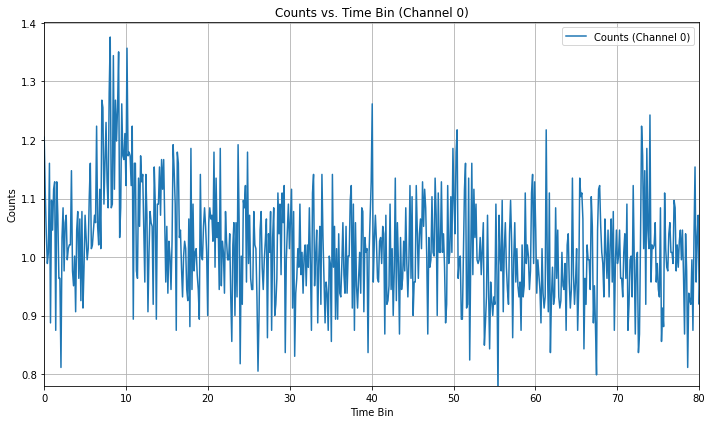

Power =  9.239999999999986 mW
Resolution is 128.0ps


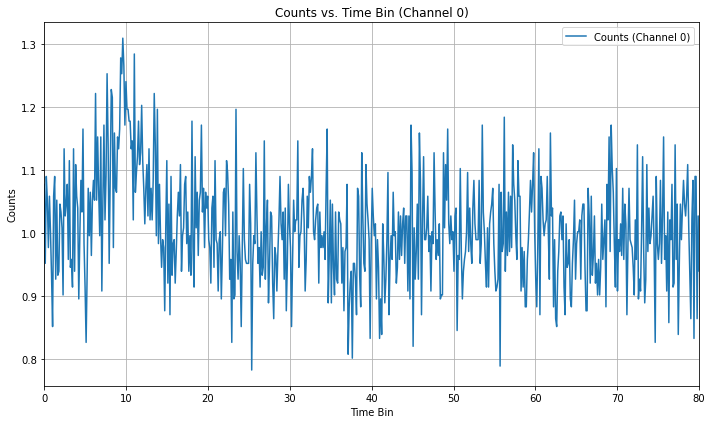

Power =  9.259999999999986 mW
Resolution is 128.0ps


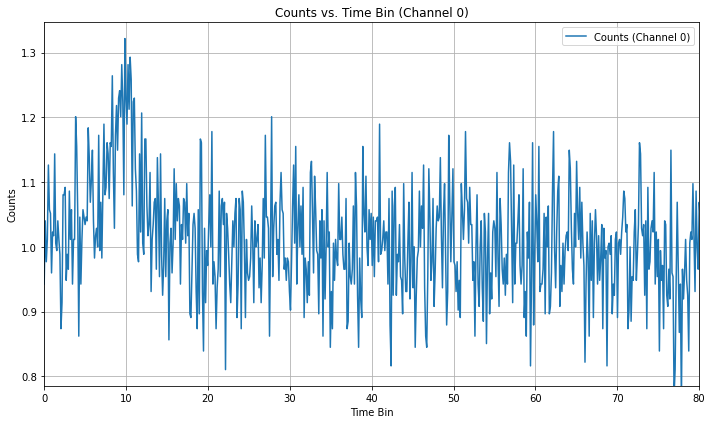

Power =  9.279999999999985 mW


In [ ]:

%load_ext autoreload
%autoreload 2
import time
import sys
import numpy as np
import Components as comp
import socket
import matplotlib.pyplot as plt
import Measurement_functions as mf
if socket.gethostname() == "ph-photonbec5":
    sys.path.append("D:/Control/PythonPackages/")
    sys.path.append("D:/Control/PiezoController/")


laser = comp.Toptica_Laser()
plot_flag_g2 = False
binning= 7
# You can change this sets the resolution as well
offset = 0
tacq = 15000 # Measurement time in millisec, you can change this
# power_list = np.append(np.append(np.arange(65, 58, 0.25)/1000,np.arange(58, 61, 0.1)/1000),np.arange(61,65,0.5)/1000)
# power_list = np.append(np.arange(16, 19, 0.25)/1000,np.arange(19, 24, 0.05)/1000)
power_list = np.arange(8.6,13,0.02)/1000
position = 2
ND1 = 23
ND2 = 23.7

for power in power_list:
    print('Power = ', power*1000, 'mW')
    laser.set(power)
    time.sleep(1)

    # if np.round(power*1000,2) == ND1:
    #     print('Please put ND1')
    #     input()
    # if np.round(power*1000,2) == ND2:
    #     print('Please put ND2')
    #     input()


    scan = mf.get_hh_data(binning, offset, tacq,plot_flag_g2)
    data = scan[0]
    resolution = scan[1]
    mf.save_hh_data(data, resolution, tacq,power*1000,position)
    counts = data/np.mean(data[350:500])
    x = np.arange(0,len(counts),1)*0.128
    plt.figure(figsize=(10, 6))
    plt.plot(x,counts, label='Counts (Channel 0)')
    plt.title('Counts vs. Time Bin (Channel 0)')
    plt.xlabel('Time Bin')
    plt.ylabel('Counts')
    plt.xlim(0,80)
    plt.ylim(np.min(counts[0:350]-0.025),np.max(counts)+0.025)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    #laser.set(0)
    #time.sleep(15)
laser.set(0)

In [ ]:
%load_ext autoreload
%autoreload 2
import time
import sys
import numpy as np
import Components as comp
import socket
import random
import Measurement_functions as mf
import matplotlib.pyplot as plt
if socket.gethostname() == "ph-photonbec5":
    sys.path.append("D:/Control/PythonPackages/")
    sys.path.append("D:/Control/PiezoController/")

path = r"D:\Data\2025\202507\20250729\24.dat"
data = np.array(mf.read_counts_from_file(path))
counts = data/np.max(data)
x = np.arange(0,len(counts),1)*0.128
plt.figure(figsize=(10, 6))
plt.plot(x,counts, label='Counts (Channel 0)')
plt.title('Counts vs. Time Bin (Channel 0)')
plt.xlabel('Time Bin')
plt.ylabel('Counts')
plt.xlim(0,80)
plt.ylim(np.min(counts[0:350]-0.025),1.005)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
